# v2 - 4. Final test (run ONCE)
Trains every model on train+val with the frozen configuration and evaluates on the locked test set. A second run is refused; if it already ran, the saved results are loaded instead. Besides accuracy/precision/recall/F1 it reports 95 % bootstrap intervals, an exact binomial test against 50 %, and **paired** tests (McNemar + bootstrap F1 difference) so that differences are not over-read.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v2"          # selects the fair-fusion study (v2); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
from toadwatch import config as C
from toadwatch import workflow as W
from toadwatch import reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v2 | seed: 2027 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v2


In [2]:
out = W.final_test()
print('combined model chosen on CV before the test:', out['chosen_combined'])
out['results'][['n','accuracy','precision','recall','f1','f1_ci_low','f1_ci_high','tn','fp','fn','tp','roc_auc','p_value']].round(4)

combined model chosen on CV before the test: combined_stacked


,n,accuracy,precision,recall,f1,f1_ci_low,f1_ci_high,tn,fp,fn,tp,roc_auc,p_value
variant,,,,,,,,,,,,,
call_only,818,0.9609,0.9748,0.9462,0.9603,0.9450,0.9736,399,10,22,387,0.9888,0.0
message_only,818,0.8667,0.8695,0.8631,0.8663,0.8424,0.8899,356,53,56,353,0.9436,0.0
combined_early,818,0.9682,0.9728,0.9633,0.9681,0.9556,0.9800,398,11,15,394,0.9940,0.0
combined_stacked,818,0.9743,0.9850,0.9633,0.9740,0.9624,0.9849,403,6,15,394,0.9967,0.0


In [3]:
out['pairwise'].round(4)

,model_a,model_b,f1_diff_a_minus_b,f1_diff_ci_low,f1_diff_ci_high,bootstrap_p,a_only_right,b_only_right,mcnemar_p
0,combined_stacked,call_only,0.0137,0.0026,0.0256,0.017,17,6,0.0347
1,combined_stacked,message_only,0.1078,0.0848,0.1313,0.000,97,9,0.0000
2,combined_stacked,combined_early,0.0060,-0.0014,0.0142,0.163,8,3,0.2266


`f1_diff_a_minus_b` > 0 means model *a* is better. If its interval contains 0 (and `mcnemar_p` > 0.05) the two models are **not** distinguishable on this test set - say so in the report.

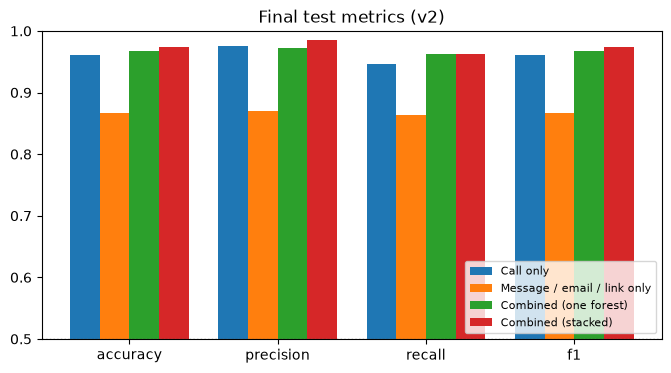

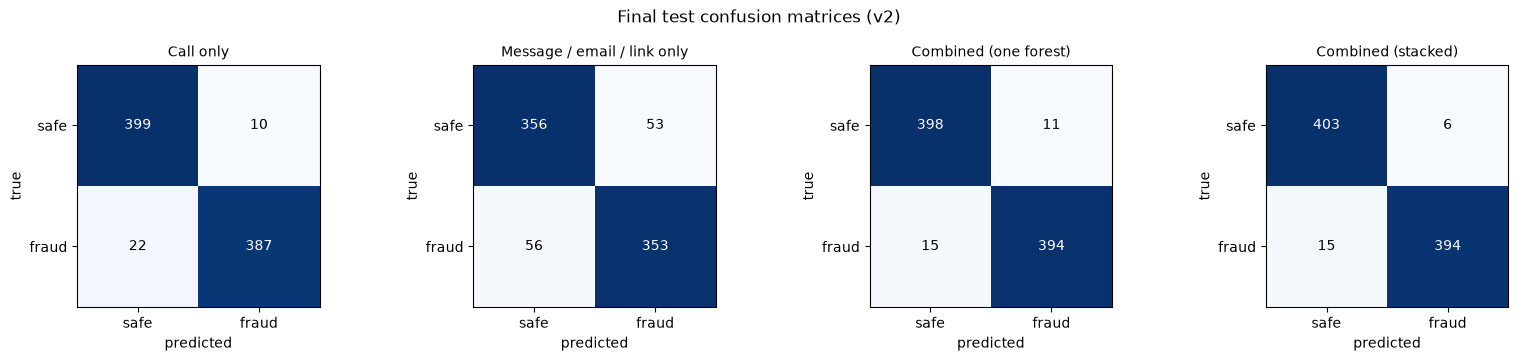

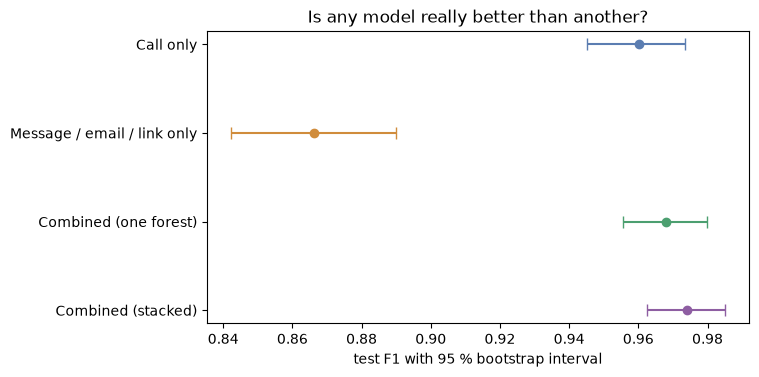

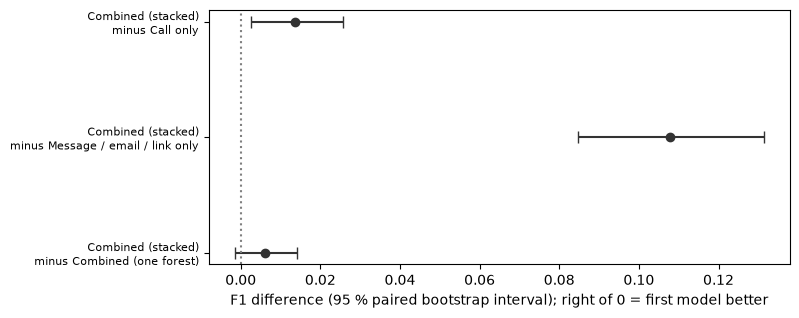

In [4]:
R.plot_metric_bars(out['results'], 'Final test metrics (v2)', 'v2_11_test_metrics')
R.plot_confusion_matrices(out['results'], 'Final test confusion matrices (v2)', 'v2_12_test_confusion')
R.plot_f1_ci(out['results'], 'v2_13_test_f1_ci'); R.plot_pairwise(out['pairwise'], 'v2_14_test_pairwise'); plt.show()

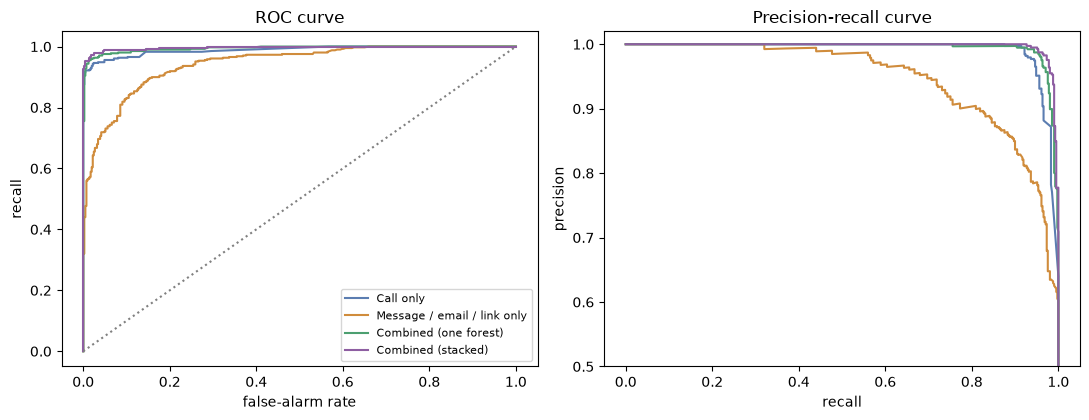

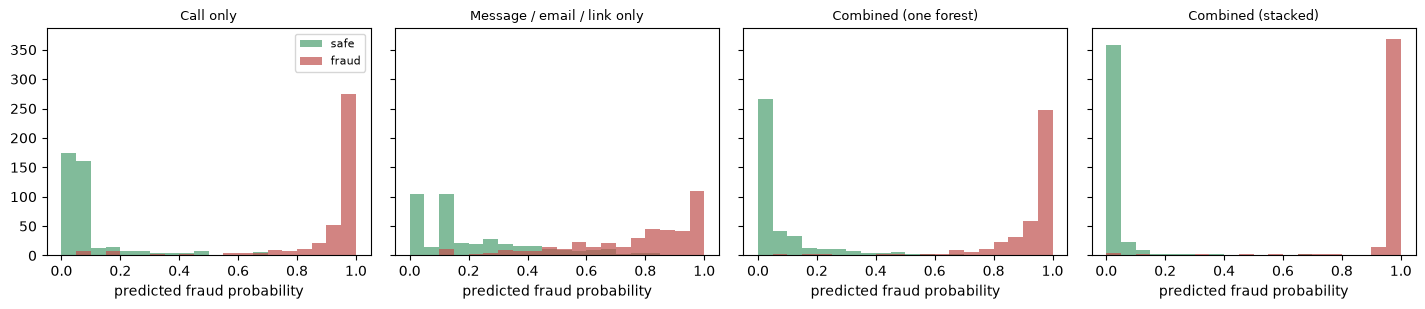

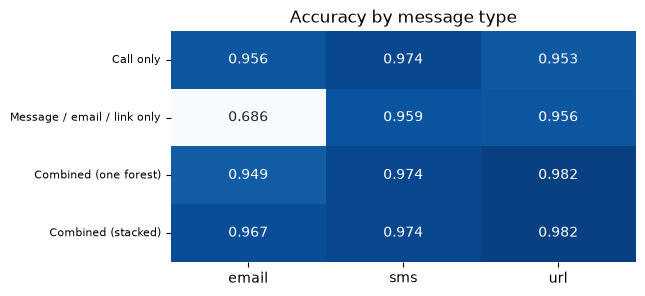

In [5]:
e = out['errors']; probas = {c[2:]: e[c] for c in e.columns if c.startswith('p_') and c != 'p_value'}
R.plot_roc_pr(e['label'], probas, 'v2_16_test_roc_pr'); R.plot_prob_hist(e['label'], probas, 'v2_17_test_prob_hist')
R.plot_kind_heatmap(out['by_msg_kind'], 'v2_15_test_by_kind'); plt.show()

In [6]:
out.get('complementarity')

,both_right,only_call_only_right,only_message_only_right,both_wrong
test_records,683,103,26,6


In [7]:
ch = out['chosen_combined']
fp = e[(e.label == 0) & (e['pred_' + ch] == 1)]; fn = e[(e.label == 1) & (e['pred_' + ch] == 0)]
print(len(fp), 'false positives;', len(fn), 'false negatives')
for title, df in [('FALSE POSITIVES', fp), ('FALSE NEGATIVES', fn)]:
    print('=====', title)
    for _, r in df.head(6).iterrows():
        print('CALL   :', r.call_text[:160].replace(chr(10), ' ')); print('MESSAGE:', r.msg_text[:160].replace(chr(10), ' '), '\n')

6 false positives; 15 false negatives
===== FALSE POSITIVES
CALL   : Hello, my name is John and I'm calling from XYZ Company. We're offering a special deal on our new software that can help you manage your business more efficient
MESSAGE: Your Thoughts on Distributed Energy Mr. Martin L. Cuilla Trader Enron Capital & Trade Resources Corp.  Dear Mr. Cuilla:  Recently, there has been a lot of discu 

CALL   : Hi, is this the tech support for Microsoft? Yeah, this is them. What seems to be the problem with your computer? I've been getting these pop-ups saying I have a
MESSAGE: FW: Franklin Hilton is out of the office until 11/6/2001 I guess we can discuss with him in the AM.    -----Original Message----- From: 	ksbrown1@aep.com@ENRON  

CALL   : Hello. Hi there! My name is Alex and I'm an insurance representative. How are you today? I'm fine, thanks. Look, I'm in the middle of something. What can I do f
MESSAGE: entrecord.com/abstracts09.html 

CALL   : Hello. Hey Mike! How's it going? I 

In [8]:
out.get('puerto_rico', 'No Puerto Rico cases in data/external/pr_cases.csv yet - report this part as not completed.')

'No Puerto Rico cases in data/external/pr_cases.csv yet - report this part as not completed.'

## Generate the deliverables
Word report + PDF and PowerPoint + PDF, rebuilt from the numbers, tables and charts of the run you just made. Output folder: `report/v2/`.

In [9]:
# Last step of the run: regenerate the Word report, report PDF, PowerPoint and presentation PDF
# from THIS run's results (written to ToadWatch_PR/report/v2/).
from toadwatch import report_builder
try:
    paths = report_builder.build_all()
except FileNotFoundError as e:
    print("Not generated yet:", e)

/home/rush/Downloads/Fase/ToadWatch_PR/toadwatch/reporting.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=folds, x="variant", y=metric, order=order, palette=[_color(v) for v in order], ax=ax, width=0.5)


/home/rush/Downloads/Fase/ToadWatch_PR/toadwatch/reporting.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=folds, x="variant", y=metric, order=order, palette=[_color(v) for v in order], ax=ax, width=0.5)


  report_docx  /home/rush/Downloads/Fase/ToadWatch_PR/report/v2/TOAD_Final_Report_v2.docx
  report_pdf   /home/rush/Downloads/Fase/ToadWatch_PR/report/v2/TOAD_Final_Report_v2.pdf
  slides_pptx  /home/rush/Downloads/Fase/ToadWatch_PR/report/v2/TOAD_Presentation_v2.pptx
  slides_pdf   /home/rush/Downloads/Fase/ToadWatch_PR/report/v2/TOAD_Presentation_v2.pdf
